# Yazılım Hata Riski ve Test Önceliklendirme

## Amaç
Yazılım modüllerine ait ölçümleri kullanarak hata içeren modülleri
tahmin etmek ve sınırlı inceleme bütçesinde test önceliklendirmesine
katkısını değerlendirmek.

## Veri kaynağı
https://www.kaggle.com/datasets/semustafacevik/software-defect-prediction

## Çalışma ilkeleri
- Orijinal veri değiştirilmeden saklanacaktır.
- Ön işleme kararları gerekçeleriyle açıklanacaktır.
- Model ve karar eşiği seçiminde test kümesi kullanılmayacaktır.
- Sonuçlar, sınırlılıklar ve başarısız denemeler dürüstçe raporlanacaktır.


In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path

PROJE_KLASORU = Path(
    "/content/drive/MyDrive/Yazilim_Hata_Riski"
)

VERI_KLASORU = PROJE_KLASORU / "data"
CIKTI_KLASORU = PROJE_KLASORU / "outputs"
RAPOR_KLASORU = PROJE_KLASORU / "reports"

for klasor in [VERI_KLASORU, CIKTI_KLASORU, RAPOR_KLASORU]:
    klasor.mkdir(parents=True, exist_ok=True)

csv_dosyalari = sorted(VERI_KLASORU.glob("*.csv"))

print("Proje klasörü:", PROJE_KLASORU)
print("\nBulunan CSV dosyaları:")

for dosya in csv_dosyalari:
    print("-", dosya.name)

if not csv_dosyalari:
    raise FileNotFoundError(
        "data klasöründe CSV bulunamadı. "
        "ZIP içinden çıkardığın CSV dosyasını bu klasöre yükle."
    )

Proje klasörü: /content/drive/MyDrive/Yazilim_Hata_Riski

Bulunan CSV dosyaları:
- jm1.csv


In [3]:
import hashlib
import json
from datetime import datetime, timezone

import pandas as pd

VERI_DOSYASI = VERI_KLASORU / "jm1.csv"

if not VERI_DOSYASI.exists():
    raise FileNotFoundError(
        f"Dosya bulunamadı: {VERI_DOSYASI.name}. "
        "Önceki hücrede listelenen dosya adını kontrol et."
    )

# Aynı veri dosyasını kullandığımızı doğrulamak için parmak izi.
sha256 = hashlib.sha256()

with VERI_DOSYASI.open("rb") as dosya:
    for parca in iter(lambda: dosya.read(1024 * 1024), b""):
        sha256.update(parca)

# Orijinal veriyi ayrı tutuyoruz.
df_ham = pd.read_csv(VERI_DOSYASI)
df = df_ham.copy()

veri_kaydi = {
    "kaynak": (
        "https://www.kaggle.com/datasets/"
        "semustafacevik/software-defect-prediction"
    ),
    "dosya_adi": VERI_DOSYASI.name,
    "sha256": sha256.hexdigest(),
    "satir_sayisi": int(df_ham.shape[0]),
    "sutun_sayisi": int(df_ham.shape[1]),
    "okuma_zamani_utc": datetime.now(timezone.utc).isoformat(),
}

with (CIKTI_KLASORU / "veri_kaydi.json").open(
    "w", encoding="utf-8"
) as dosya:
    json.dump(veri_kaydi, dosya, ensure_ascii=False, indent=2)

print("Veri başarıyla okundu.")
print("Satır ve sütun sayısı:", df.shape)
print("SHA-256:", veri_kaydi["sha256"])

display(df.head())

Veri başarıyla okundu.
Satır ve sütun sayısı: (10885, 22)
SHA-256: 7f8aff7353f7932c0d058011b554066375e52ef4d8a385454f957b0ad2b60094


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1,1,1,1,1,1,1,1,1,True
2,72.0,7.0,1.0,6.0,198.0,1134.13,0.05,20.31,55.85,23029.10,...,51,10,8,1,17,36,112,86,13,True
3,190.0,3.0,1.0,3.0,600.0,4348.76,0.06,17.06,254.87,74202.67,...,129,29,28,2,17,135,329,271,5,True
4,37.0,4.0,1.0,4.0,126.0,599.12,0.06,17.19,34.86,10297.30,...,28,1,6,0,11,16,76,50,7,True


In [4]:
print("SÜTUNLAR")
print(df.columns.tolist())

print("\nVERİ YAPISI")
df.info()

print("\nPANDAS TARAFINDAN ALGILANAN EKSİK DEĞERLER")
display(df.isna().sum().sort_values(ascending=False))

print("\nTAMAMEN AYNI OLAN TEKRAR SATIR SAYISI")
print(df.duplicated().sum())

print("\nSAYISAL DEĞİŞKENLERİN ÖZETİ")
display(df.describe().T)

SÜTUNLAR
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

VERİ YAPISI
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10885 entries, 0 to 10884
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   loc                10885 non-null  float64
 1   v(g)               10885 non-null  float64
 2   ev(g)              10885 non-null  float64
 3   iv(g)              10885 non-null  float64
 4   n                  10885 non-null  float64
 5   v                  10885 non-null  float64
 6   l                  10885 non-null  float64
 7   d                  10885 non-null  float64
 8   i                  10885 non-null  float64
 9   e                  10885 non-null  float64
 10  b                  10885 non-null  float64
 11  t                  10885 non-null  

,0
loc,0
v(g),0
ev(g),0
iv(g),0
n,0
v,0
l,0
d,0
i,0
e,0



TAMAMEN AYNI OLAN TEKRAR SATIR SAYISI
1973

SAYISAL DEĞİŞKENLERİN ÖZETİ


,count,mean,std,min,25%,50%,75%,max
loc,10885.0,42.016178,76.593332,1.0,11.00,23.00,46.00,3442.00
v(g),10885.0,6.348590,13.019695,1.0,2.00,3.00,7.00,470.00
ev(g),10885.0,3.401047,6.771869,1.0,1.00,1.00,3.00,165.00
iv(g),10885.0,4.001599,9.116889,1.0,1.00,2.00,4.00,402.00
n,10885.0,114.389738,249.502091,0.0,14.00,49.00,119.00,8441.00
v,10885.0,673.758017,1938.856196,0.0,48.43,217.13,621.48,80843.08
l,10885.0,0.135335,0.160538,0.0,0.03,0.08,0.16,1.30
d,10885.0,14.177237,18.709900,0.0,3.00,9.09,18.90,418.20
i,10885.0,29.439544,34.418313,0.0,11.86,21.93,36.78,569.78
e,10885.0,36836.365343,434367.801255,0.0,161.94,2031.02,11416.43,31079782.27


## 2. Veri Kalitesi Denetimi

İlk incelemede beş girdi sütununun metin türünde okunduğu ve
1.973 tekrar satır bulunduğu görülmüştür.

Bu aşamada:
- Sayıya dönüştürülemeyen değerler belirlenecek.
- Hedef sınıfların dağılımı incelenecek.
- Aynı girdilere sahip kayıtların etiketleri karşılaştırılacak.
- Şüpheli sayım değerleri raporlanacaktır.

Henüz satır silinmeyecek ve eksik değer doldurulmayacaktır.

In [5]:
# Her çalıştırmada orijinal veriden başlayarak aynı sonucu üretelim.
df_kontrol = df_ham.copy()

HEDEF = "defects"
ozellikler = [sutun for sutun in df_kontrol.columns if sutun != HEDEF]

donusum_raporu = []

for sutun in ozellikler:
    orijinal = df_kontrol[sutun]
    sayisal = pd.to_numeric(orijinal, errors="coerce")

    # Orijinalde dolu olduğu hâlde sayıya çevrilemeyen değerler.
    sorunlu = orijinal.notna() & sayisal.isna()

    donusum_raporu.append({
        "sutun": sutun,
        "ilk_veri_turu": str(orijinal.dtype),
        "sayiya_cevrilemeyen_adet": int(sorunlu.sum()),
        "sorunlu_degerler": str(
            orijinal.loc[sorunlu].astype(str).unique().tolist()
        ),
        "toplam_eksik": int(sayisal.isna().sum()),
    })

    df_kontrol[sutun] = sayisal

donusum_raporu = pd.DataFrame(donusum_raporu)

display(donusum_raporu)

donusum_raporu.to_csv(
    CIKTI_KLASORU / "sayisal_donusum_denetimi.csv",
    index=False
)

,sutun,ilk_veri_turu,sayiya_cevrilemeyen_adet,sorunlu_degerler,toplam_eksik
0,loc,float64,0,[],0
1,v(g),float64,0,[],0
2,ev(g),float64,0,[],0
3,iv(g),float64,0,[],0
4,n,float64,0,[],0
5,v,float64,0,[],0
6,l,float64,0,[],0
7,d,float64,0,[],0
8,i,float64,0,[],0
9,e,float64,0,[],0


In [6]:
print("Hedef sütunun veri türü:", df_kontrol[HEDEF].dtype)
print("Hedef sütundaki eksik değer:", df_kontrol[HEDEF].isna().sum())

sinif_tablosu = (
    df_kontrol[HEDEF]
    .value_counts(dropna=False)
    .rename_axis("defects")
    .reset_index(name="adet")
)

sinif_tablosu["yuzde"] = (
    100 * sinif_tablosu["adet"] / len(df_kontrol)
).round(2)

display(sinif_tablosu)

sinif_tablosu.to_csv(
    CIKTI_KLASORU / "ham_veri_sinif_dagilimi.csv",
    index=False
)

Hedef sütunun veri türü: bool
Hedef sütundaki eksik değer: 0


,defects,adet,yuzde
0,False,8779,80.65
1,True,2106,19.35


In [7]:
# Bütün sütunları aynı olan kayıtlar.
tam_tekrar = df_kontrol.duplicated()

# Hedef hariç bütün girdileri aynı olan kayıtlar.
ayni_girdi = df_kontrol.duplicated(
    subset=ozellikler,
    keep=False
)

# Aynı girdiler için hem True hem False etiketi var mı?
etiket_cesidi = (
    df_kontrol
    .groupby(ozellikler, dropna=False)[HEDEF]
    .transform("nunique")
)

celiskili = etiket_cesidi.gt(1)

tekrar_ozeti = pd.DataFrame({
    "kontrol": [
        "İlk kopya dışındaki tam tekrar satırları",
        "Aynı girdiye sahip gruplardaki tüm satırlar",
        "Çelişkili etiket grubundaki tüm satırlar",
    ],
    "adet": [
        int(tam_tekrar.sum()),
        int(ayni_girdi.sum()),
        int(celiskili.sum()),
    ],
})

display(tekrar_ozeti)

if celiskili.any():
    print("Çelişkili etiketlere ait örnek kayıtlar:")
    display(df_kontrol.loc[celiskili].head(10))

tekrar_ozeti.to_csv(
    CIKTI_KLASORU / "tekrar_ve_etiket_denetimi.csv",
    index=False
)

,kontrol,adet
0,İlk kopya dışındaki tam tekrar satırları,1973
1,Aynı girdiye sahip gruplardaki tüm satırlar,2730
2,Çelişkili etiket grubundaki tüm satırlar,889


Çelişkili etiketlere ait örnek kayıtlar:


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
8,24.0,2.0,1.0,2.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0,0,0,0,0.0,0.0,0.0,0.0,3.0,True
60,8.0,1.0,1.0,1.0,14.0,46.51,0.33,3.00,15.50,139.52,...,4,0,2,0,5.0,5.0,8.0,6.0,1.0,True
74,20.0,1.0,1.0,1.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,True
78,12.0,3.0,1.0,2.0,22.0,88.00,0.12,8.33,10.56,733.33,...,9,0,1,0,10.0,6.0,12.0,10.0,5.0,True
86,18.0,1.0,1.0,1.0,18.0,72.00,0.30,3.30,21.82,237.60,...,14,0,2,0,6.0,10.0,7.0,11.0,1.0,True
90,4.0,1.0,1.0,1.0,10.0,30.00,0.50,2.00,15.00,60.00,...,2,0,0,0,4.0,4.0,6.0,4.0,1.0,True
91,4.0,1.0,1.0,1.0,10.0,30.00,0.50,2.00,15.00,60.00,...,2,0,0,0,4.0,4.0,6.0,4.0,1.0,True
92,4.0,1.0,1.0,1.0,10.0,30.00,0.50,2.00,15.00,60.00,...,2,0,0,0,4.0,4.0,6.0,4.0,1.0,True
93,4.0,1.0,1.0,1.0,10.0,30.00,0.50,2.00,15.00,60.00,...,2,0,0,0,4.0,4.0,6.0,4.0,1.0,True
94,4.0,1.0,1.0,1.0,10.0,30.00,0.50,2.00,15.00,60.00,...,2,0,0,0,4.0,4.0,6.0,4.0,1.0,True


In [8]:
import numpy as np

# Adları ve ilk inceleme doğrultusunda tam sayı olması beklenen
# ölçümleri işaretliyoruz. Bu kontrol tek başına silme nedeni değildir.
sayim_sutunlari = [
    "loc", "v(g)", "ev(g)", "iv(g)", "n",
    "lOCode", "lOComment", "lOBlank", "locCodeAndComment",
    "uniq_Op", "uniq_Opnd", "total_Op", "total_Opnd",
    "branchCount"
]

ondalik_maskesi = pd.DataFrame(
    False,
    index=df_kontrol.index,
    columns=sayim_sutunlari
)

for sutun in sayim_sutunlari:
    degerler = df_kontrol[sutun]

    ondalik_maskesi[sutun] = (
        degerler.notna()
        & ~np.isclose(degerler, np.round(degerler))
    )

supheli_satir = ondalik_maskesi.any(axis=1)

print(
    "En az bir sayım ölçümü ondalıklı olan satır sayısı:",
    int(supheli_satir.sum())
)

display(
    ondalik_maskesi.sum()
    .rename("ondalik_deger_adedi")
    .to_frame()
)

display(df_kontrol.loc[supheli_satir].head(10))

df_kontrol.loc[supheli_satir].to_csv(
    CIKTI_KLASORU / "incelenecek_ondalik_sayim_kayitlari.csv",
    index_label="orijinal_satir_indeksi"
)

En az bir sayım ölçümü ondalıklı olan satır sayısı: 1


,ondalik_deger_adedi
loc,1
v(g),1
ev(g),1
iv(g),1
n,1
lOCode,0
lOComment,0
lOBlank,0
locCodeAndComment,0
uniq_Op,1


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.3,1.3,1.3,1.3,1.3,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False


In [9]:
# Önceki denetim hücrelerinin çalıştığını kontrol et.
gerekli_degiskenler = [
    "df_kontrol",
    "donusum_raporu",
    "sinif_tablosu",
    "tekrar_ozeti",
    "celiskili",
    "supheli_satir",
]

eksik_degiskenler = [
    isim for isim in gerekli_degiskenler
    if isim not in globals()
]

if eksik_degiskenler:
    raise RuntimeError(
        "Önce veri denetimi hücrelerini sırayla çalıştır. "
        f"Eksik değişkenler: {eksik_degiskenler}"
    )

print("1. SAYIYA DÖNÜŞTÜRME SORUNLARI")
display(
    donusum_raporu.loc[
        donusum_raporu["toplam_eksik"].gt(0)
    ]
)

print("\n2. HEDEF SINIF DAĞILIMI")
display(sinif_tablosu)

print("\n3. TEKRAR VE ETİKET DENETİMİ")
display(tekrar_ozeti)

print("\n4. ŞÜPHELİ SAYIM KAYITLARI")
print("Satır sayısı:", int(supheli_satir.sum()))
display(df_kontrol.loc[supheli_satir].head(10))

# Veri üzerinde yaptığımız dönüşümü, eksikleri doldurmadan kaydet.
# Orijinal CSV dosyasının üzerine yazılmaz.
df_kontrol.to_csv(
    CIKTI_KLASORU / "sayisala_donusturulmus_veri.csv",
    index=False
)

rapor_notu = f"""# Veri Kalitesi Denetimi — Ara Bulgular

- Ham veri: {df_ham.shape[0]} satır, {df_ham.shape[1]} sütun.
- Hedef değişken: defects.
- Girdi sayısı: {len(ozellikler)}.
- Ham veride ilk kopya dışındaki tam tekrar sayısı:
  {int(df_ham.duplicated().sum())}.
- Sayısala dönüşümden sonra eksik değer içeren satır sayısı:
  {int(df_kontrol[ozellikler].isna().any(axis=1).sum())}.
- Çelişkili etiket gruplarındaki toplam satır sayısı:
  {int(celiskili.sum())}.
- En az bir sayım ölçümü ondalıklı olan satır sayısı:
  {int(supheli_satir.sum())}.

## Bu aşamada uygulanan işlemler
- Orijinal veri korunmuştur.
- Girdi sütunları sayısala dönüştürülmüştür.
- Sayıya dönüştürülemeyen değerler eksik olarak işaretlenmiştir.
- Henüz kayıt silinmemiş, eksik değer doldurulmamış
  ve model eğitilmemiştir.

## Sonraki kararlar
- Tekrar ve çelişkili etiket politikası belirlenecek.
- Şüpheli kayıtlar değerlendirilerek gerekçeli karar verilecek.
- Aynı girdilerin farklı veri kümelerine geçmesi engellenecek.
- Eksik değer doldurma ve ölçekleme eğitim verisinde öğrenilecek.

Bu dosya ara denetim kaydıdır; nihai sonuç raporu değildir.
"""

not_dosyasi = RAPOR_KLASORU / "veri_denetimi_ara_notlari.md"
not_dosyasi.write_text(rapor_notu, encoding="utf-8")

print("\nDenetim verisi ve rapor notları Drive'a kaydedildi.")

1. SAYIYA DÖNÜŞTÜRME SORUNLARI


,sutun,ilk_veri_turu,sayiya_cevrilemeyen_adet,sorunlu_degerler,toplam_eksik
16,uniq_Op,object,5,['?'],5
17,uniq_Opnd,object,5,['?'],5
18,total_Op,object,5,['?'],5
19,total_Opnd,object,5,['?'],5
20,branchCount,object,5,['?'],5



2. HEDEF SINIF DAĞILIMI


,defects,adet,yuzde
0,False,8779,80.65
1,True,2106,19.35



3. TEKRAR VE ETİKET DENETİMİ


,kontrol,adet
0,İlk kopya dışındaki tam tekrar satırları,1973
1,Aynı girdiye sahip gruplardaki tüm satırlar,2730
2,Çelişkili etiket grubundaki tüm satırlar,889



4. ŞÜPHELİ SAYIM KAYITLARI
Satır sayısı: 1


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.3,1.3,1.3,1.3,1.3,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False



Denetim verisi ve rapor notları Drive'a kaydedildi.


## 3. Analiz Verisi ve Veri Ayrımı

### Veri kalitesi kararları
- Sayıya dönüştürülemeyen değerler eksik olarak işaretlenmiştir.
- Eksik değerler eğitim verisinden öğrenilen medyanlarla
  model Pipeline'ı içinde doldurulacaktır.
- Modül kimlikleri bulunmadığından tekrar kayıtların kaynağı
  kesin olarak belirlenememektedir. Ana analizde korunacaktır.
- Aynı girdilere sahip kayıtlar, etiketleri farklı olsa bile,
  aynı veri kümesinde tutulacaktır.
- Ondalıklı sayım ölçümleri içeren tek kayıt, geçerliliği
  doğrulanamadığı için ana analizden ayrılmıştır.
  Kaydın hatalı olduğu kesin olarak iddia edilmemektedir.

### Değerlendirme düzeni
Yaklaşık %60 eğitim, %20 doğrulama ve %20 test ayrımı yapılacaktır.
Ayrım satırlar yerine aynı girdilere sahip kayıt grupları üzerinden
yapıldığı için satır oranları tam olarak bu yüzdeler olmayabilir.

Model ve karar eşiği doğrulama verisiyle seçilecek;
test verisi son değerlendirmeye kadar kullanılmayacaktır.

Bu ayrım, aynı girdilerin kümeler arasında paylaşılmasını önler.
Farklı yazılım projelerine veya gelecekteki verilere genelleme
başarısını tek başına kanıtlamaz.

In [10]:
# Şüpheli kaydı silmek yerine ayrı dosyada saklıyoruz.
df_kontrol.loc[supheli_satir].to_csv(
    CIKTI_KLASORU / "ana_analizden_ayrilan_kayitlar.csv",
    index_label="orijinal_satir_indeksi"
)

df_analiz = df_kontrol.loc[~supheli_satir].copy()

# Orijinal satır indekslerini koruyoruz.
assert df_analiz.index.is_unique
assert df_analiz[HEDEF].notna().all()
assert set(df_analiz[HEDEF].unique()).issubset({True, False})

X = df_analiz[ozellikler].copy()
y = df_analiz[HEDEF].astype(int)

# Aynı 21 girdiye sahip kayıtlar aynı grup numarasını alır.
# Eksikler de grup belirlerken birlikte değerlendirilir.
gruplar = (
    df_analiz
    .groupby(ozellikler, dropna=False, sort=False)
    .ngroup()
    .rename("grup")
)

assert gruplar.notna().all()

print("Analize alınan satır:", len(df_analiz))
print("Girdi sayısı:", X.shape[1])
print("Benzersiz girdi grubu:", gruplar.nunique())
print("Eksik değer içeren satır:", X.isna().any(axis=1).sum())

print("\nHedef sınıflar: 0 = hatasız, 1 = hatalı")
display(y.value_counts().sort_index())

Analize alınan satır: 10884
Girdi sayısı: 21
Benzersiz girdi grubu: 8823
Eksik değer içeren satır: 5

Hedef sınıflar: 0 = hatasız, 1 = hatalı


,count
defects,
0,8778
1,2106


In [11]:
from sklearn.model_selection import GroupShuffleSplit

TOHUM = 42

# Önce grupların yaklaşık %20'sini test için ayır.
ilk_ayrim = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=TOHUM
)

gelistirme_poz, test_poz = next(
    ilk_ayrim.split(X, y, groups=gruplar)
)

# Kalan %80'in dörtte biri doğrulama:
# Toplam grupların yaklaşık %20'si.
ikinci_ayrim = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=TOHUM
)

egitim_yerel, dogrulama_yerel = next(
    ikinci_ayrim.split(
        X.iloc[gelistirme_poz],
        y.iloc[gelistirme_poz],
        groups=gruplar.iloc[gelistirme_poz]
    )
)

egitim_poz = gelistirme_poz[egitim_yerel]
dogrulama_poz = gelistirme_poz[dogrulama_yerel]

X_train = X.iloc[egitim_poz].copy()
X_val = X.iloc[dogrulama_poz].copy()
X_test = X.iloc[test_poz].copy()

y_train = y.iloc[egitim_poz].copy()
y_val = y.iloc[dogrulama_poz].copy()
y_test = y.iloc[test_poz].copy()

# Aynı girdi grubu iki farklı kümede bulunmamalı.
egitim_gruplari = set(gruplar.iloc[egitim_poz])
dogrulama_gruplari = set(gruplar.iloc[dogrulama_poz])
test_gruplari = set(gruplar.iloc[test_poz])

assert egitim_gruplari.isdisjoint(dogrulama_gruplari)
assert egitim_gruplari.isdisjoint(test_gruplari)
assert dogrulama_gruplari.isdisjoint(test_gruplari)

assert len(X_train) + len(X_val) + len(X_test) == len(X)

for hedef in [y_train, y_val, y_test]:
    assert hedef.nunique() == 2, "Bir kümede iki sınıf da bulunmuyor."

bolum_ozeti = pd.DataFrame([
    {
        "kume": isim,
        "satir": len(hedef),
        "satir_yuzdesi": round(100 * len(hedef) / len(y), 2),
        "hatali_yuzdesi": round(100 * hedef.mean(), 2)
    }
    for isim, hedef in [
        ("egitim", y_train),
        ("dogrulama", y_val),
        ("test", y_test)
    ]
])

display(bolum_ozeti)
print("Kontrol başarılı: kümeler arasında ortak girdi grubu yok.")

,kume,satir,satir_yuzdesi,hatali_yuzdesi
0,egitim,6650,61.1,18.12
1,dogrulama,2166,19.9,21.10
2,test,2068,19.0,21.47


Kontrol başarılı: kümeler arasında ortak girdi grubu yok.


In [12]:
ayrim_kaydi = pd.DataFrame({
    "orijinal_satir_indeksi": df_analiz.index,
    "grup": gruplar.to_numpy(),
    "kume": ""
}).set_index("orijinal_satir_indeksi")

ayrim_kaydi.loc[X_train.index, "kume"] = "egitim"
ayrim_kaydi.loc[X_val.index, "kume"] = "dogrulama"
ayrim_kaydi.loc[X_test.index, "kume"] = "test"

assert ayrim_kaydi["kume"].ne("").all()

ayrim_kaydi.to_csv(CIKTI_KLASORU / "veri_ayrimi.csv")

bolum_ozeti.to_csv(
    CIKTI_KLASORU / "veri_ayrimi_ozeti.csv",
    index=False
)

for isim, girdiler, hedef in [
    ("egitim", X_train, y_train),
    ("dogrulama", X_val, y_val),
    ("test", X_test, y_test)
]:
    kayit = girdiler.copy()
    kayit[HEDEF] = hedef

    kayit.to_csv(
        CIKTI_KLASORU / f"{isim}_verisi.csv",
        index_label="orijinal_satir_indeksi"
    )

kararlar = {
    "random_state": TOHUM,
    "ayrim_yontemi": "GroupShuffleSplit",
    "grup_tanimi": "Hedef haric tum girdilerin ayni olmasi",
    "tekrar_kayitlar": "Korundu; ayni grupta tutuldu",
    "celiskili_etiketler": "Korundu; ayni grupta tutuldu",
    "ayrilan_supheli_satir": int(supheli_satir.sum()),
    "eksik_degerler": "Henuz doldurulmadi",
    "test_kullanimi": "Yalnizca son degerlendirme",
}

(CIKTI_KLASORU / "analiz_kararlari.json").write_text(
    json.dumps(kararlar, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Veri ayrımı ve analiz kararları Drive'a kaydedildi.")

Veri ayrımı ve analiz kararları Drive'a kaydedildi.


## 4. Eğitim Verisi Üzerinde Keşif Analizi

Model geliştirme kararlarını yönlendirecek keşif analizi yalnızca
eğitim verisi üzerinde yapılmaktadır.

İncelenen başlıklar:
1. Hatalı ve hatasız modüllerin dağılımı.
2. Kod uzunluğu ve karmaşıklık ölçümlerinin sınıflara göre dağılımı.
3. Kod uzunluğu aralıklarında gözlenen hata oranı.
4. Seçilen ölçümler arasındaki Spearman korelasyonu.

Grafikler ilişkiyi gösterir; neden-sonuç kanıtı olarak yorumlanmaz.
Tekrar kayıtlar korunduğu için sonuçlar benzersiz modüller yerine
veri setindeki kayıtların dağılımını yansıtır.

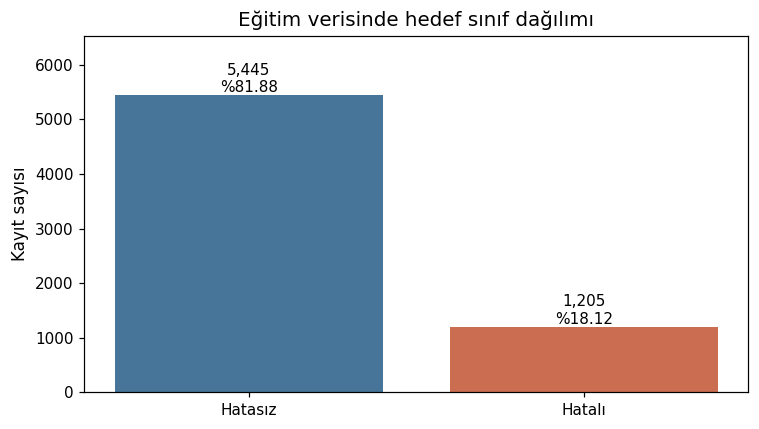

In [13]:
import matplotlib.pyplot as plt

GRAFIK_KLASORU = CIKTI_KLASORU / "grafikler"
GRAFIK_KLASORU.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "font.size": 10
})

eda = X_train.copy()
eda["defects"] = y_train
eda["sinif"] = y_train.map({0: "Hatasız", 1: "Hatalı"})

def grafik_kaydet(fig, dosya_adi):
    fig.tight_layout()
    fig.savefig(
        GRAFIK_KLASORU / dosya_adi,
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

adetler = y_train.value_counts().reindex([0, 1], fill_value=0)

fig, ax = plt.subplots(figsize=(7, 4))

cubuklar = ax.bar(
    ["Hatasız", "Hatalı"],
    adetler.values,
    color=["#467599", "#CB6D51"]
)

for cubuk, adet in zip(cubuklar, adetler.values):
    ax.text(
        cubuk.get_x() + cubuk.get_width() / 2,
        adet,
        f"{adet:,}\n%{100 * adet / len(y_train):.2f}",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, adetler.max() * 1.20)
ax.set_title("Eğitim verisinde hedef sınıf dağılımı")
ax.set_ylabel("Kayıt sayısı")

grafik_kaydet(fig, "01_egitim_sinif_dagilimi.png")

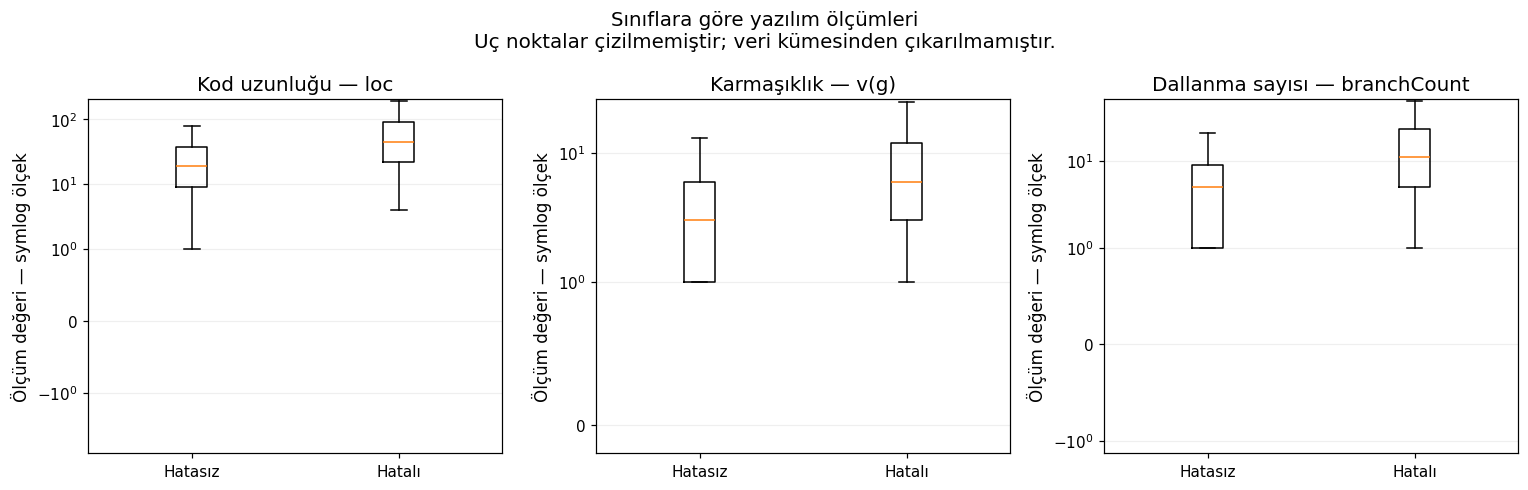

loc              v(g)            branchCount           
        median       mean median       mean      median       mean
sinif                                                             
Hatalı    45.0  79.008299    6.0  11.583402        11.0  21.221114
Hatasız   19.0  32.427548    3.0   4.850138         5.0   8.510013

In [14]:
incelenecek_olcumler = {
    "loc": "Kod uzunluğu — loc",
    "v(g)": "Karmaşıklık — v(g)",
    "branchCount": "Dallanma sayısı — branchCount"
}

fig, eksenler = plt.subplots(1, 3, figsize=(14, 4.5))

for ax, (sutun, baslik) in zip(
    eksenler, incelenecek_olcumler.items()
):
    sinif_degerleri = [
        eda.loc[eda["defects"].eq(sinif), sutun].dropna()
        for sinif in [0, 1]
    ]

    ax.boxplot(sinif_degerleri, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Hatasız", "Hatalı"])

    # Sıfır değerlerini de gösterebilen sıkıştırılmış ölçek.
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(baslik)
    ax.set_ylabel("Ölçüm değeri — symlog ölçek")
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Sınıflara göre yazılım ölçümleri\n"
    "Uç noktalar çizilmemiştir; veri kümesinden çıkarılmamıştır.",
    fontsize=13
)

grafik_kaydet(fig, "02_siniflara_gore_olcumler.png")

olcum_ozeti = (
    eda.groupby("sinif")[list(incelenecek_olcumler)]
    .agg(["median", "mean"])
)

display(olcum_ozeti)

olcum_ozeti.to_csv(
    CIKTI_KLASORU / "siniflara_gore_olcum_ozeti.csv"
)

,kayit_sayisi,hatali_sayisi,hata_orani,hata_yuzdesi
loc,,,,
"(0.999, 8.0]",1385,84,0.060650,6.064982
"(8.0, 17.0]",1319,134,0.101592,10.159212
"(17.0, 28.0]",1293,180,0.139211,13.921114
"(28.0, 55.0]",1343,294,0.218913,21.891288
"(55.0, 1882.0]",1310,513,0.391603,39.160305


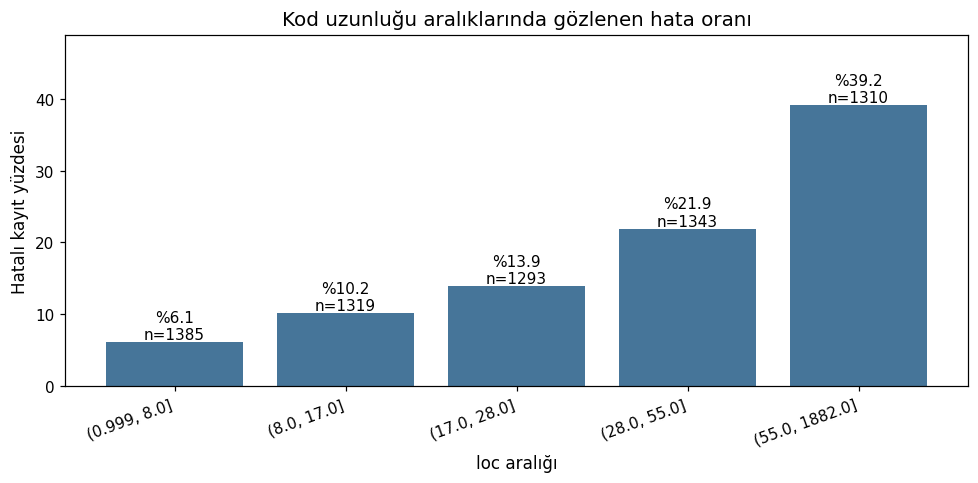

In [15]:
# Aralıklar yalnızca eğitim verisiyle belirleniyor.
loc_araliklari = pd.qcut(
    eda["loc"],
    q=5,
    duplicates="drop"
)

loc_ozeti = (
    eda.groupby(loc_araliklari, observed=True)["defects"]
    .agg(kayit_sayisi="size", hatali_sayisi="sum", hata_orani="mean")
)

loc_ozeti["hata_yuzdesi"] = 100 * loc_ozeti["hata_orani"]

display(loc_ozeti)

fig, ax = plt.subplots(figsize=(9, 4.5))

x = np.arange(len(loc_ozeti))

ax.bar(x, loc_ozeti["hata_yuzdesi"], color="#467599")

ax.set_xticks(x)
ax.set_xticklabels(
    [str(aralik) for aralik in loc_ozeti.index],
    rotation=20,
    ha="right"
)

for konum, (_, satir) in enumerate(loc_ozeti.iterrows()):
    ax.text(
        konum,
        satir["hata_yuzdesi"],
        f"%{satir['hata_yuzdesi']:.1f}\nn={int(satir['kayit_sayisi'])}",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, max(10, loc_ozeti["hata_yuzdesi"].max() * 1.25))
ax.set_title("Kod uzunluğu aralıklarında gözlenen hata oranı")
ax.set_xlabel("loc aralığı")
ax.set_ylabel("Hatalı kayıt yüzdesi")

grafik_kaydet(fig, "03_kod_uzunlugu_hata_orani.png")

loc_ozeti.to_csv(
    CIKTI_KLASORU / "kod_uzunlugu_hata_orani.csv"
)

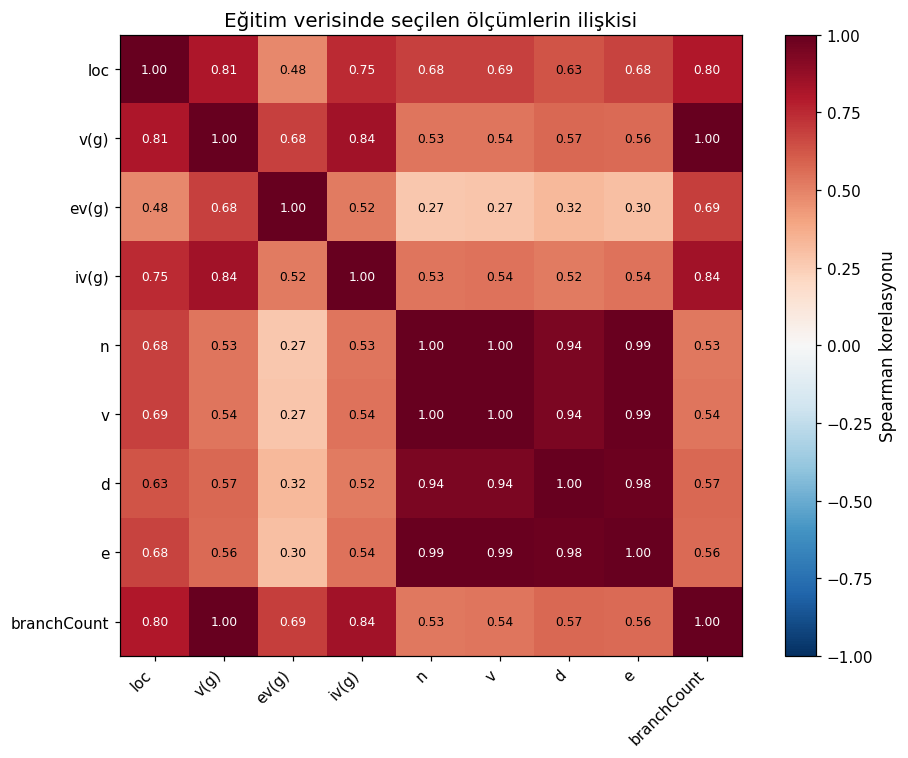

Dört grafik ve destekleyici tablolar Drive'a kaydedildi.


In [16]:
korelasyon_sutunlari = [
    "loc", "v(g)", "ev(g)", "iv(g)",
    "n", "v", "d", "e", "branchCount"
]

korelasyon = eda[korelasyon_sutunlari].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))

gorsel = ax.imshow(
    korelasyon,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(korelasyon_sutunlari)))
ax.set_yticks(range(len(korelasyon_sutunlari)))

ax.set_xticklabels(korelasyon_sutunlari, rotation=45, ha="right")
ax.set_yticklabels(korelasyon_sutunlari)

for satir in range(len(korelasyon_sutunlari)):
    for sutun in range(len(korelasyon_sutunlari)):
        deger = korelasyon.iloc[satir, sutun]
        ax.text(
            sutun, satir, f"{deger:.2f}",
            ha="center",
            va="center",
            color="white" if abs(deger) > 0.65 else "black",
            fontsize=8
        )

fig.colorbar(gorsel, ax=ax, label="Spearman korelasyonu")
ax.set_title("Eğitim verisinde seçilen ölçümlerin ilişkisi")

grafik_kaydet(fig, "04_olcum_korelasyonlari.png")

korelasyon.to_csv(
    CIKTI_KLASORU / "egitim_spearman_korelasyonu.csv"
)

print("Dört grafik ve destekleyici tablolar Drive'a kaydedildi.")

### Keşif Analizi Bulguları

Eğitim verisinde hatalı kayıtların kod uzunluğu medyanı 45,
hatasız kayıtların medyanı 19'dur. v(g) karmaşıklık medyanları
sırasıyla 6 ve 3'tür.

Kod uzunluğunun en düşük aralığında gözlenen hata oranı yaklaşık
%6,06 iken en yüksek aralığında %39,16'dır.

Bu ilişkiler nedensellik kanıtı değildir. Dağılımlar tek başına
kesin sınıflandırma sağlamaz. Modelin pratik katkısı,
kod uzunluğuna göre önceliklendirme yaklaşımıyla da karşılaştırılacaktır.

## 5. Başlangıç Modelleri ve Doğrulama Karşılaştırması

Üç yaklaşım karşılaştırılacaktır:
- DummyClassifier: Her kaydı çoğunluk sınıfına atayan referans model.
- Logistic Regression: Ölçeklendirilmiş girdilerle doğrusal başlangıç modeli.
- Random Forest: Doğrusal olmayan ilişkileri değerlendiren ağaç topluluğu.

Eksik değerler yalnızca eğitim verisinden öğrenilen medyanlarla
doldurulacaktır. Logistic Regression girdileri ayrıca ölçeklendirilecektir.
Bu işlemler Pipeline içinde uygulanacaktır.

İki öğrenen modelde sınıf dengesizliğine karşı balanced sınıf
ağırlıkları kullanılacaktır. Bunlar gerçek hata maliyetleri değildir.

Model karşılaştırmasında öncelikli ölçüt Average Precision (AP)
olacaktır. AP, pozitif sınıfın farklı karar eşiklerindeki precision
ve recall davranışını özetler; trapez yöntemiyle hesaplanan PR-AUC ile
birebir aynı ölçüt değildir.

İlk sınıflandırma karşılaştırması 0,50 eşiğiyle yapılacaktır.
Karar eşiği daha sonra yalnızca doğrulama verisiyle değerlendirilecektir.
Test verisi bu aşamada kullanılmayacaktır.

In [18]:
import platform
import sklearn
import joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

MODEL_KLASORU = CIKTI_KLASORU / "modeller"
MODEL_KLASORU.mkdir(parents=True, exist_ok=True)

modeller = {
    "Dummy": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            C=1.0,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=5000,
            random_state=TOHUM
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced",
            random_state=TOHUM,
            n_jobs=-1
        ))
    ])
}

surumler = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "joblib": joblib.__version__
}

(CIKTI_KLASORU / "kutuphane_surumleri.json").write_text(
    json.dumps(surumler, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Modeller oluşturuldu. Henüz eğitim yapılmadı.")
display(pd.Series(surumler, name="surum"))

Modeller oluşturuldu. Henüz eğitim yapılmadı.


,surum
python,3.13.16
pandas,2.2.3
numpy,2.1.3
scikit_learn,1.6.1
joblib,1.6.0


In [19]:
from time import perf_counter

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

egitilmis_modeller = {}
val_skorlari = {}
val_tahminleri = {}
sonuc_satirlari = []

model_dosyalari = {
    "Dummy": "dummy.joblib",
    "Logistic Regression": "logistic_regression.joblib",
    "Random Forest": "random_forest.joblib"
}

for isim, pipeline in modeller.items():
    baslangic = perf_counter()

    # fit yalnızca eğitim verisini görür.
    pipeline.fit(X_train, y_train)

    egitim_suresi = perf_counter() - baslangic

    siniflar = pipeline.named_steps["model"].classes_
    pozitif_sutun = list(siniflar).index(1)

    skor = pipeline.predict_proba(X_val)[:, pozitif_sutun]
    tahmin = (skor >= 0.50).astype(int)

    egitilmis_modeller[isim] = pipeline
    val_skorlari[isim] = skor
    val_tahminleri[isim] = tahmin

    sonuc_satirlari.append({
        "model": isim,
        "accuracy": accuracy_score(y_val, tahmin),
        "precision": precision_score(
            y_val, tahmin, zero_division=0
        ),
        "recall": recall_score(
            y_val, tahmin, zero_division=0
        ),
        "f1": f1_score(
            y_val, tahmin, zero_division=0
        ),
        "average_precision": average_precision_score(y_val, skor),
        "roc_auc": roc_auc_score(y_val, skor),
        "egitim_suresi_sn": egitim_suresi
    })

    joblib.dump(
        pipeline,
        MODEL_KLASORU / model_dosyalari[isim]
    )

    print(f"{isim}: eğitim tamamlandı.")

val_sonuclari = (
    pd.DataFrame(sonuc_satirlari)
    .sort_values(
        "average_precision",
        ascending=False,
        kind="stable"
    )
    .reset_index(drop=True)
)

display(val_sonuclari.round(4))

val_sonuclari.to_csv(
    CIKTI_KLASORU / "ilk_model_dogrulama_sonuclari.csv",
    index=False
)

val_kaydi = pd.DataFrame(
    {"gercek_etiket": y_val},
    index=y_val.index
)

for isim in modeller:
    val_kaydi[f"{isim}_skor"] = val_skorlari[isim]
    val_kaydi[f"{isim}_tahmin"] = val_tahminleri[isim]

val_kaydi.to_csv(
    CIKTI_KLASORU / "dogrulama_tahminleri.csv",
    index_label="orijinal_satir_indeksi"
)

print("Modeller ve doğrulama sonuçları Drive'a kaydedildi.")
print("Test verisi kullanılmadı.")

Dummy: eğitim tamamlandı.
Logistic Regression: eğitim tamamlandı.
Random Forest: eğitim tamamlandı.


,model,accuracy,precision,recall,f1,average_precision,roc_auc,egitim_suresi_sn
0,Random Forest,0.7664,0.4497,0.4792,0.4640,0.4417,0.7182,6.6162
1,Logistic Regression,0.6907,0.3608,0.6039,0.4517,0.4208,0.6901,0.5064
2,Dummy,0.7890,0.0000,0.0000,0.0000,0.2110,0.5000,0.0337


Modeller ve doğrulama sonuçları Drive'a kaydedildi.
Test verisi kullanılmadı.


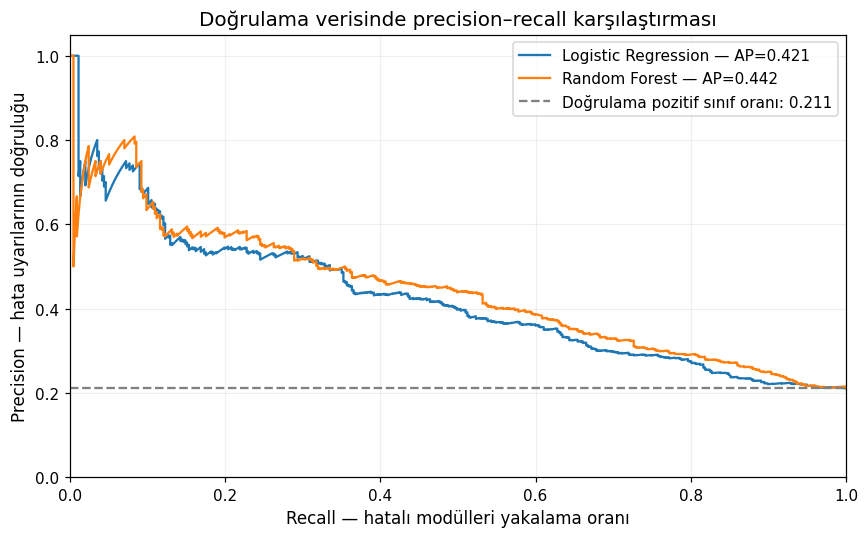

In [20]:
from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(figsize=(8, 5))

for isim in ["Logistic Regression", "Random Forest"]:
    precision, recall, _ = precision_recall_curve(
        y_val, val_skorlari[isim]
    )

    ap = average_precision_score(
        y_val, val_skorlari[isim]
    )

    ax.plot(
        recall,
        precision,
        label=f"{isim} — AP={ap:.3f}"
    )

ax.axhline(
    y_val.mean(),
    color="gray",
    linestyle="--",
    label=f"Doğrulama pozitif sınıf oranı: {y_val.mean():.3f}"
)

ax.set(
    xlabel="Recall — hatalı modülleri yakalama oranı",
    ylabel="Precision — hata uyarılarının doğruluğu",
    title="Doğrulama verisinde precision–recall karşılaştırması",
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.legend()
ax.grid(alpha=0.2)

grafik_kaydet(fig, "05_dogrulama_precision_recall.png")

## 6. Model ve Karar Eşiği Seçimi

Başlangıç modelleri arasında doğrulama Average Precision değeri
en yüksek olan Random Forest seçilmiştir.

0,50 karar eşiğinde Random Forest'ın recall değeri yaklaşık %47,92,
precision değeri %44,97'dir. Logistic Regression daha yüksek recall
sağlarken daha fazla yanlış alarm üretmektedir.

Gerçek hata maliyetleri bilinmediği için karar eşiği,
doğrulama verisinde F1 skorunu en yüksek yapan değer olarak seçilecektir.
Eşit F1 durumunda daha yüksek eşik tercih edilecektir.

Bu seçim bir işletme için en iyi maliyet kararını garanti etmez.
Model ve eşik aynı doğrulama kümesiyle seçildiğinden, doğrulama
sonuçları iyimser olabilir. Son performans ayrı test kümesinde ölçülecektir.

Model bu aşamada yeniden eğitilmeyecektir. Seçilen eşik,
mevcut eğitim verisiyle eğitilmiş model için sabitlenecektir.

In [22]:
# Önceden belirlediğimiz ana ölçüt: doğrulama AP.
secilen_model_adi = (
    val_sonuclari
    .sort_values(
        ["average_precision", "model"],
        ascending=[False, True]
    )
    .iloc[0]["model"]
)

secilen_model = egitilmis_modeller[secilen_model_adi]
secilen_val_skoru = val_skorlari[secilen_model_adi]

# Her benzersiz skor, farklı bir sınıflandırma kararı oluşturabilir.
p, r, esikler = precision_recall_curve(
    y_val,
    secilen_val_skoru
)

# Son precision/recall noktasının karşılık gelen eşiği yoktur.
p = p[:-1]
r = r[:-1]

f1_degerleri = np.divide(
    2 * p * r,
    p + r,
    out=np.zeros_like(p),
    where=(p + r) != 0
)

esik_tablosu = pd.DataFrame({
    "esik": esikler,
    "precision": p,
    "recall": r,
    "f1": f1_degerleri
})

en_iyi_satir = (
    esik_tablosu
    .sort_values(
        ["f1", "esik"],
        ascending=[False, False]
    )
    .iloc[0]
)

SECILEN_ESIK = float(en_iyi_satir["esik"])

print("Seçilen model:", secilen_model_adi)
print(f"Seçilen eşik: {SECILEN_ESIK:.6f}")
print("\nDoğrulama verisindeki eşik seçimi:")
display(en_iyi_satir.to_frame("deger"))

esik_tablosu.to_csv(
    CIKTI_KLASORU / "dogrulama_esik_taramasi.csv",
    index=False
)

Seçilen model: Random Forest
Seçilen eşik: 0.470372

Doğrulama verisindeki eşik seçimi:


,deger
esik,0.470372
precision,0.436036
recall,0.529540
f1,0.478261


,yaklasim,esik,accuracy,precision,recall,f1,yanlis_alarm_FP,kacirilan_hatali_FN,yakalanan_hatali_TP,incelemeye_isaretlenen
0,Başlangıç eşiği,0.5000,0.7664,0.4497,0.4792,0.4640,268,238,219,487
1,Doğrulamada seçilen eşik,0.4704,0.7562,0.4360,0.5295,0.4783,313,215,242,555


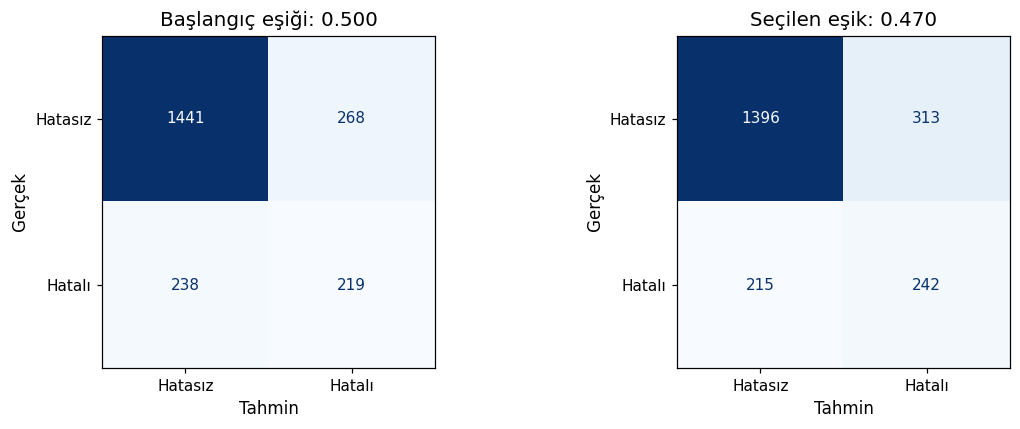

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

esik_karsilastirma_satirlari = []

for aciklama, esik in [
    ("Başlangıç eşiği", 0.50),
    ("Doğrulamada seçilen eşik", SECILEN_ESIK)
]:
    tahmin = (secilen_val_skoru >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_val, tahmin, labels=[0, 1]
    ).ravel()

    esik_karsilastirma_satirlari.append({
        "yaklasim": aciklama,
        "esik": esik,
        "accuracy": accuracy_score(y_val, tahmin),
        "precision": precision_score(
            y_val, tahmin, zero_division=0
        ),
        "recall": recall_score(
            y_val, tahmin, zero_division=0
        ),
        "f1": f1_score(
            y_val, tahmin, zero_division=0
        ),
        "yanlis_alarm_FP": int(fp),
        "kacirilan_hatali_FN": int(fn),
        "yakalanan_hatali_TP": int(tp),
        "incelemeye_isaretlenen": int(tahmin.sum())
    })

esik_karsilastirma = pd.DataFrame(
    esik_karsilastirma_satirlari
)

display(esik_karsilastirma.round(4))

esik_karsilastirma.to_csv(
    CIKTI_KLASORU / "dogrulama_esik_karsilastirma.csv",
    index=False
)

fig, eksenler = plt.subplots(1, 2, figsize=(11, 4))

for ax, esik, baslik in zip(
    eksenler,
    [0.50, SECILEN_ESIK],
    ["Başlangıç eşiği", "Seçilen eşik"]
):
    tahmin = (secilen_val_skoru >= esik).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        tahmin,
        labels=[0, 1],
        display_labels=["Hatasız", "Hatalı"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{baslik}: {esik:.3f}")
    ax.set_xlabel("Tahmin")
    ax.set_ylabel("Gerçek")

grafik_kaydet(fig, "06_dogrulama_esik_confusion_matrix.png")

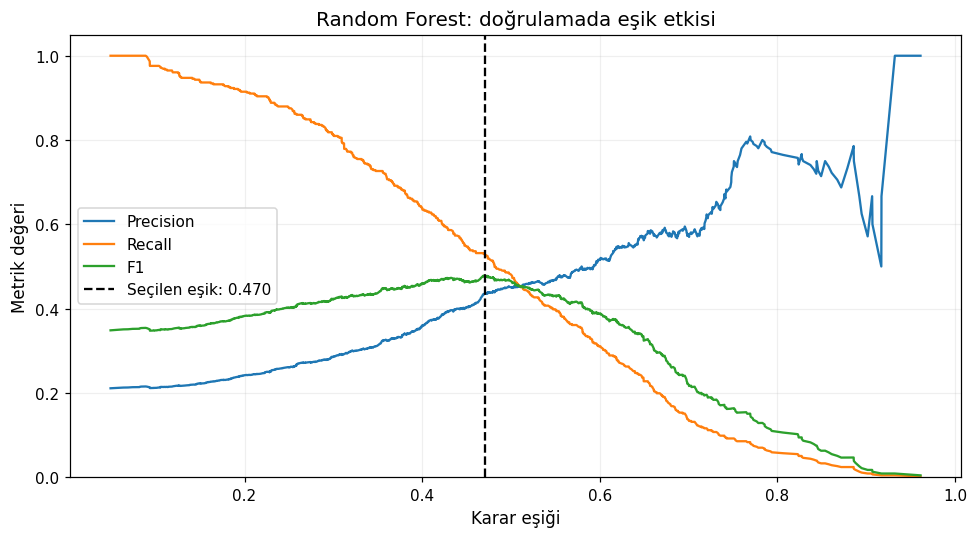

Model ve eşik seçimi Drive'a kaydedildi.
Test verisi henüz değerlendirilmedi.


In [24]:
fig, ax = plt.subplots(figsize=(9, 5))

for metrik, etiket in [
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("f1", "F1")
]:
    ax.plot(
        esik_tablosu["esik"],
        esik_tablosu[metrik],
        label=etiket
    )

ax.axvline(
    SECILEN_ESIK,
    linestyle="--",
    color="black",
    label=f"Seçilen eşik: {SECILEN_ESIK:.3f}"
)

ax.set(
    xlabel="Karar eşiği",
    ylabel="Metrik değeri",
    title=f"{secilen_model_adi}: doğrulamada eşik etkisi",
    ylim=(0, 1.05)
)

ax.legend()
ax.grid(alpha=0.2)

grafik_kaydet(fig, "07_dogrulama_esik_etkisi.png")

secim_kaydi = {
    "model": secilen_model_adi,
    "model_secim_olcutu": "Dogrulama Average Precision",
    "esik": SECILEN_ESIK,
    "esik_secim_olcutu": "Dogrulama F1 maksimumu",
    "esitlik_kurali": "Daha yuksek esik",
    "yeniden_egitim": False,
    "test_kullanildi": False
}

(CIKTI_KLASORU / "sabitlenen_model_ve_esik.json").write_text(
    json.dumps(secim_kaydi, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

joblib.dump(
    {
        "pipeline": secilen_model,
        "secim": secim_kaydi,
        "ozellikler": ozellikler,
        "surumler": surumler
    },
    MODEL_KLASORU / "secilen_model_paketi.joblib"
)

print("Model ve eşik seçimi Drive'a kaydedildi.")
print("Test verisi henüz değerlendirilmedi.")

## 7. Sınırlı İnceleme Bütçesiyle Önceliklendirme

Kayıtların yalnızca %10, %20 veya %30'u incelenebildiğinde,
bu grubun gerçek hatalı kayıtların ne kadarını kapsadığı ölçülecektir.

Karşılaştırılan yaklaşımlar:
- Seçilen modelin risk skoruna göre sıralama.
- Kod uzunluğuna (loc) göre sıralama.
- 500 tekrarlı rastgele seçim.

Ana ölçüt, incelenen gruptaki hatalı kayıt sayısının tüm hatalı
kayıt sayısına oranıdır. İncelenen grubun precision değeri de verilecektir.

Bu deney karar eşiğinden bağımsızdır.
Eşit skorlarda sıralama, etiketlerden bağımsız sabit rastgele
bir öncelikle belirlenecektir.

Bütçe kayıt sayısına dayanmaktadır; gerçek test süresini veya
parasal tasarrufu ölçmez. Tekrarlar korunduğundan sonuçlar
benzersiz modüller yerine veri kayıtları üzerinden yorumlanacaktır.

In [25]:
BUTCE_ORANLARI = [0.10, 0.20, 0.30]
RASTGELE_TEKRAR = 500

def butce_deneyi(y_gercek, model_skoru, loc_degerleri, tohum=42):
    etiketler = np.asarray(y_gercek, dtype=int)
    skorlar = np.asarray(model_skoru, dtype=float)
    uzunluklar = np.asarray(loc_degerleri, dtype=float)

    n = len(etiketler)
    toplam_hatali = int(etiketler.sum())

    assert n == len(skorlar) == len(uzunluklar)
    assert toplam_hatali > 0
    assert np.isfinite(skorlar).all()
    assert np.isfinite(uzunluklar).all()

    # Eşit skorları orijinal satır sırası veya etiketle çözmüyoruz.
    rng_esitlik = np.random.default_rng(tohum)
    esitlik_onceligi = rng_esitlik.random(n)

    siralamalar = {
        "Model": np.lexsort((esitlik_onceligi, -skorlar)),
        "Kod uzunluğu": np.lexsort(
            (esitlik_onceligi, -uzunluklar)
        )
    }

    # Her tekrarda tam bir rastgele sıralama.
    rng_rastgele = np.random.default_rng(tohum + 1)
    rastgele_siralamalar = [
        rng_rastgele.permutation(n)
        for _ in range(RASTGELE_TEKRAR)
    ]

    satirlar = []

    for oran in BUTCE_ORANLARI:
        # Bütçeyi aşmamak için aşağı yuvarlıyoruz.
        k = max(1, int(np.floor(n * oran)))

        for yontem, sira in siralamalar.items():
            yakalanan = int(etiketler[sira[:k]].sum())

            satirlar.append({
                "yontem": yontem,
                "butce": oran,
                "incelenen_kayit": k,
                "gercek_butce": k / n,
                "yakalanan_hatali": yakalanan,
                "kapsama": yakalanan / toplam_hatali,
                "precision": yakalanan / k
            })

        rastgele_yakalanan = np.array([
            etiketler[sira[:k]].sum()
            for sira in rastgele_siralamalar
        ])

        satirlar.append({
            "yontem": "Rastgele seçim ortalaması",
            "butce": oran,
            "incelenen_kayit": k,
            "gercek_butce": k / n,
            "yakalanan_hatali": rastgele_yakalanan.mean(),
            "kapsama": rastgele_yakalanan.mean() / toplam_hatali,
            "precision": rastgele_yakalanan.mean() / k
        })

    return pd.DataFrame(satirlar)

,yontem,butce,incelenen_kayit,gercek_butce,yakalanan_hatali,kapsama,precision
0,Model,0.1,216,0.0997,120.000,0.2626,0.5556
1,Kod uzunluğu,0.1,216,0.0997,109.000,0.2385,0.5046
2,Rastgele seçim ortalaması,0.1,216,0.0997,45.880,0.1004,0.2124
3,Model,0.2,433,0.1999,199.000,0.4354,0.4596
4,Kod uzunluğu,0.2,433,0.1999,188.000,0.4114,0.4342
5,Rastgele seçim ortalaması,0.2,433,0.1999,91.804,0.2009,0.2120
6,Model,0.3,649,0.2996,259.000,0.5667,0.3991
7,Kod uzunluğu,0.3,649,0.2996,252.000,0.5514,0.3883
8,Rastgele seçim ortalaması,0.3,649,0.2996,137.454,0.3008,0.2118


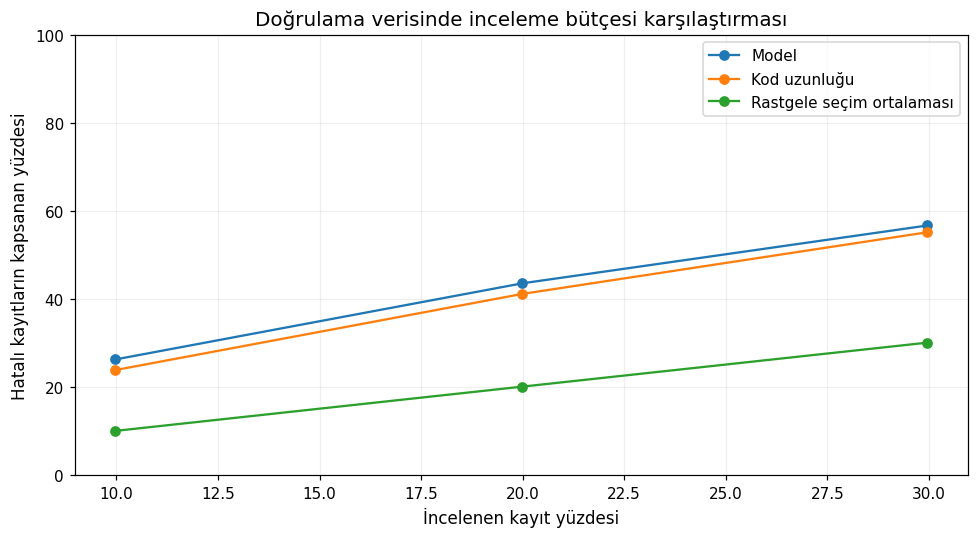

Bütçe deneyi ve grafik Drive'a kaydedildi.
Model ve eşik değiştirilmedi; test verisi kullanılmadı.


In [26]:
butce_val = butce_deneyi(
    y_gercek=y_val,
    model_skoru=secilen_val_skoru,
    loc_degerleri=X_val["loc"],
    tohum=TOHUM
)

display(butce_val.round(4))

butce_val.to_csv(
    CIKTI_KLASORU / "dogrulama_butce_deneyi.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 5))

for yontem, tablo in butce_val.groupby("yontem", sort=False):
    ax.plot(
        100 * tablo["gercek_butce"],
        100 * tablo["kapsama"],
        marker="o",
        label=yontem
    )

ax.set(
    xlabel="İncelenen kayıt yüzdesi",
    ylabel="Hatalı kayıtların kapsanan yüzdesi",
    title="Doğrulama verisinde inceleme bütçesi karşılaştırması",
    ylim=(0, 100)
)

ax.legend()
ax.grid(alpha=0.2)

grafik_kaydet(fig, "08_dogrulama_butce_deneyi.png")

print("Bütçe deneyi ve grafik Drive'a kaydedildi.")
print("Model ve eşik değiştirilmedi; test verisi kullanılmadı.")

## 8. Sabitlenen Modelin Test Değerlendirmesi

Random Forest modeli ve doğrulama verisinde seçilen karar eşiği
değiştirilmeden test verisine uygulanacaktır. Yeniden eğitim yapılmayacaktır.

Accuracy, precision, recall, F1, Average Precision, ROC-AUC ve
confusion matrix raporlanacaktır. Ayrıca önceden belirlenen
%10, %20 ve %30 inceleme bütçeleriyle önceliklendirme karşılaştırılacaktır.

Test sonuçları model veya eşik seçimini değiştirmek için kullanılmayacaktır.
Bu değerlendirme aynı veri kaynağında ayrılmış gruplara aittir;
farklı şirketlere veya yazılım projelerine genellemeyi kanıtlamaz.

In [27]:
# Seçimi Drive'daki kayıtla karşılaştır.
sabit_secim = json.loads(
    (CIKTI_KLASORU / "sabitlenen_model_ve_esik.json")
    .read_text(encoding="utf-8")
)

assert sabit_secim["model"] == secilen_model_adi
assert np.isclose(
    sabit_secim["esik"], SECILEN_ESIK,
    rtol=0, atol=1e-12
)

# fit çağrısı yok: mevcut eğitilmiş model kullanılıyor.
siniflar = secilen_model.named_steps["model"].classes_
pozitif_sutun = list(siniflar).index(1)

test_skoru = secilen_model.predict_proba(X_test)[:, pozitif_sutun]
test_tahmini = (test_skoru >= SECILEN_ESIK).astype(int)

assert np.isfinite(test_skoru).all()

test_metrikleri = {
    "model": secilen_model_adi,
    "esik": SECILEN_ESIK,
    "kayit_sayisi": len(y_test),
    "hatali_kayit_sayisi": int(y_test.sum()),
    "accuracy": accuracy_score(y_test, test_tahmini),
    "precision": precision_score(
        y_test, test_tahmini, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_tahmini, zero_division=0
    ),
    "f1": f1_score(
        y_test, test_tahmini, zero_division=0
    ),
    "average_precision": average_precision_score(
        y_test, test_skoru
    ),
    "roc_auc": roc_auc_score(y_test, test_skoru)
}

test_sonuclari = pd.DataFrame([test_metrikleri])
display(test_sonuclari.round(4))

test_sonuclari.to_csv(
    CIKTI_KLASORU / "nihai_test_sonuclari.csv",
    index=False
)

# Sonraki hata analizinde de kullanacağız.
test_detay = X_test.copy()
test_detay["gercek_etiket"] = y_test
test_detay["risk_skoru"] = test_skoru
test_detay["tahmin"] = test_tahmini

test_detay["sonuc_turu"] = np.select(
    [
        (y_test.to_numpy() == 1) & (test_tahmini == 1),
        (y_test.to_numpy() == 0) & (test_tahmini == 1),
        (y_test.to_numpy() == 1) & (test_tahmini == 0)
    ],
    ["TP", "FP", "FN"],
    default="TN"
)

test_detay.to_csv(
    CIKTI_KLASORU / "nihai_test_tahminleri.csv",
    index_label="orijinal_satir_indeksi"
)

print("Test sonuçları ve kayıt bazında tahminler Drive'a kaydedildi.")

,model,esik,kayit_sayisi,hatali_kayit_sayisi,accuracy,precision,recall,f1,average_precision,roc_auc
0,Random Forest,0.4704,2068,444,0.7331,0.4032,0.5068,0.4491,0.413,0.7184


Test sonuçları ve kayıt bazında tahminler Drive'a kaydedildi.


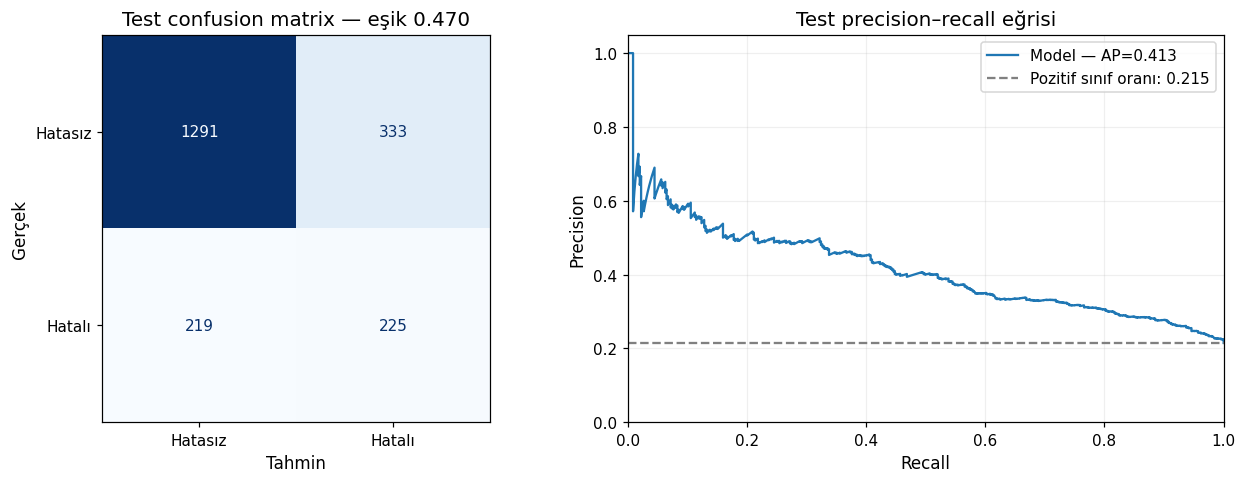

Yakalanan hatalı kayıt (TP): 225
Kaçırılan hatalı kayıt (FN): 219
Yanlış alarm (FP): 333
Doğru hatasız tahmini (TN): 1291


In [28]:
fig, eksenler = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_tahmini,
    labels=[0, 1],
    display_labels=["Hatasız", "Hatalı"],
    cmap="Blues",
    colorbar=False,
    ax=eksenler[0]
)

eksenler[0].set_title(
    f"Test confusion matrix — eşik {SECILEN_ESIK:.3f}"
)
eksenler[0].set_xlabel("Tahmin")
eksenler[0].set_ylabel("Gerçek")

test_precision, test_recall, _ = precision_recall_curve(
    y_test, test_skoru
)

eksenler[1].plot(
    test_recall,
    test_precision,
    label=f"Model — AP={test_metrikleri['average_precision']:.3f}"
)

eksenler[1].axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label=f"Pozitif sınıf oranı: {y_test.mean():.3f}"
)

eksenler[1].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Test precision–recall eğrisi",
    xlim=(0, 1),
    ylim=(0, 1.05)
)

eksenler[1].legend()
eksenler[1].grid(alpha=0.2)

grafik_kaydet(fig, "09_nihai_test_degerlendirmesi.png")

tn, fp, fn, tp = confusion_matrix(
    y_test, test_tahmini, labels=[0, 1]
).ravel()

print(f"Yakalanan hatalı kayıt (TP): {tp}")
print(f"Kaçırılan hatalı kayıt (FN): {fn}")
print(f"Yanlış alarm (FP): {fp}")
print(f"Doğru hatasız tahmini (TN): {tn}")

,yontem,butce,incelenen_kayit,gercek_butce,yakalanan_hatali,kapsama,precision
0,Model,0.1,206,0.0996,101.00,0.2275,0.4903
1,Kod uzunluğu,0.1,206,0.0996,109.00,0.2455,0.5291
2,Rastgele seçim ortalaması,0.1,206,0.0996,44.67,0.1006,0.2168
3,Model,0.2,413,0.1997,182.00,0.4099,0.4407
4,Kod uzunluğu,0.2,413,0.1997,176.00,0.3964,0.4262
5,Rastgele seçim ortalaması,0.2,413,0.1997,89.07,0.2006,0.2157
6,Model,0.3,620,0.2998,239.00,0.5383,0.3855
7,Kod uzunluğu,0.3,620,0.2998,233.00,0.5248,0.3758
8,Rastgele seçim ortalaması,0.3,620,0.2998,133.60,0.3009,0.2155


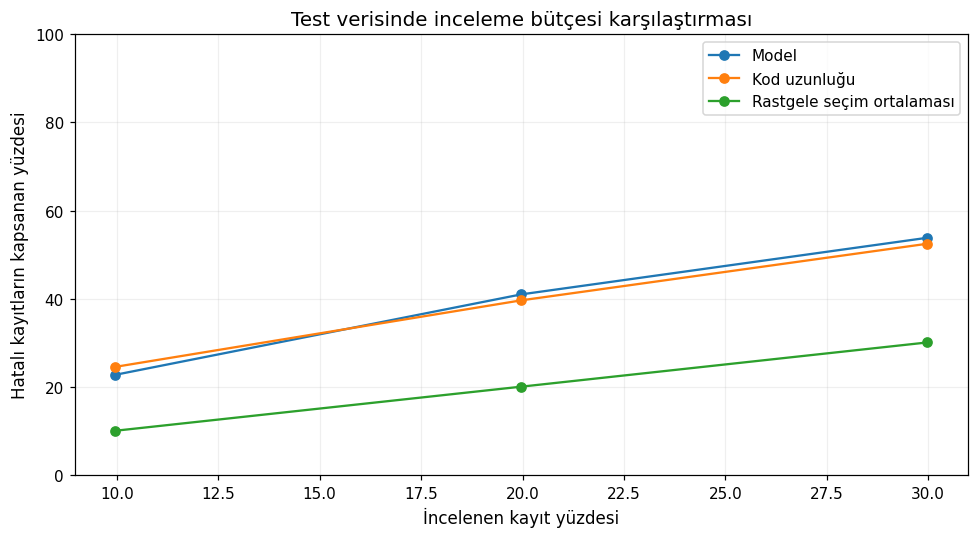

%20 bütçede model − kod uzunluğu farkı: +6 hatalı kayıt, +1.35 yüzde puan kapsama.
Test değerlendirmesi tamamlandı; model ve eşik değiştirilmedi.


In [29]:
# Doğrulamada kullandığımız fonksiyon ve bütçeler aynen korunuyor.
butce_test = butce_deneyi(
    y_gercek=y_test,
    model_skoru=test_skoru,
    loc_degerleri=X_test["loc"],
    tohum=TOHUM
)

display(butce_test.round(4))

butce_test.to_csv(
    CIKTI_KLASORU / "nihai_test_butce_deneyi.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 5))

for yontem, tablo in butce_test.groupby("yontem", sort=False):
    ax.plot(
        100 * tablo["gercek_butce"],
        100 * tablo["kapsama"],
        marker="o",
        label=yontem
    )

ax.set(
    xlabel="İncelenen kayıt yüzdesi",
    ylabel="Hatalı kayıtların kapsanan yüzdesi",
    title="Test verisinde inceleme bütçesi karşılaştırması",
    ylim=(0, 100)
)

ax.legend()
ax.grid(alpha=0.2)

grafik_kaydet(fig, "10_test_butce_deneyi.png")

# %20 bütçedeki farkı, yönünü değiştirmeden raporla.
butce20 = butce_test.loc[
    np.isclose(butce_test["butce"], 0.20)
].set_index("yontem")

ek_hatali = (
    butce20.loc["Model", "yakalanan_hatali"]
    - butce20.loc["Kod uzunluğu", "yakalanan_hatali"]
)

kapsama_farki = 100 * (
    butce20.loc["Model", "kapsama"]
    - butce20.loc["Kod uzunluğu", "kapsama"]
)

print(
    "%20 bütçede model − kod uzunluğu farkı: "
    f"{ek_hatali:+.0f} hatalı kayıt, "
    f"{kapsama_farki:+.2f} yüzde puan kapsama."
)

print("Test değerlendirmesi tamamlandı; model ve eşik değiştirilmedi.")